# 广告账户 ROI 分析（代码模板）
照着每一步跑，看不懂的地方先运行看结果。

In [1]:
# 第1步：导入工具
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
plt.rcParams['font.sans-serif']=['SimHei']   # 中文显示
plt.rcParams['axes.unicode_minus']=False

In [5]:
# 第2步：读数据
df = pd.read_excel('ad_account_data.xlsx')
df.head()

,日期,计划ID,渠道,计划名称,消耗,曝光,点击,转化数,转化价值
0,2026-08-01,S001,搜索,品牌词,799.41,170428,9872,1203,573440.22
1,2026-08-01,S002,搜索,品类词,1040.76,225689,16053,2104,979922.62
2,2026-08-01,S003,搜索,竞品词-华为,1336.83,341065,14197,1773,762196.17
3,2026-08-01,S004,搜索,竞品词-苹果,1040.15,253528,17415,918,426215.78
4,2026-08-01,S005,搜索,开箱对比词,811.59,169269,12274,1025,470461.57


## 第3步：数据清洗

In [6]:
# 看看数据长什么样
df.shape        # 多少行多少列
df.info()       # 每列类型、有没有缺失
df.isnull().sum()  # 缺失值统计

<class 'pandas.DataFrame'>
RangeIndex: 1200 entries, 0 to 1199
Data columns (total 9 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   日期      1200 non-null   str    
 1   计划ID    1200 non-null   str    
 2   渠道      1200 non-null   str    
 3   计划名称    1200 non-null   str    
 4   消耗      1200 non-null   float64
 5   曝光      1200 non-null   int64  
 6   点击      1200 non-null   int64  
 7   转化数     1200 non-null   int64  
 8   转化价值    1200 non-null   float64
dtypes: float64(2), int64(3), str(4)
memory usage: 84.5 KB


日期      0
计划ID    0
渠道      0
计划名称    0
消耗      0
曝光      0
点击      0
转化数     0
转化价值    0
dtype: int64

In [7]:
# 异常检查
df['消耗'].describe()
(df['点击'] > df['曝光']).sum()   # 点击不该大于曝光
df['消耗'].min()                # 消耗不该为负

274.83

## 第4步：计算指标

In [8]:
df['CTR'] = df['点击'] / df['曝光']
df['CVR'] = df['转化数'] / df['点击']
df['CPA'] = df['消耗'] / df['转化数'].replace(0, np.nan)
df['ROI'] = df['转化价值'] / df['消耗']
df.head()

,日期,计划ID,渠道,计划名称,消耗,曝光,点击,转化数,转化价值,CTR,CVR,CPA,ROI
0,2026-08-01,S001,搜索,品牌词,799.41,170428,9872,1203,573440.22,0.057925,0.121860,0.664514,717.329305
1,2026-08-01,S002,搜索,品类词,1040.76,225689,16053,2104,979922.62,0.071129,0.131066,0.494658,941.545236
2,2026-08-01,S003,搜索,竞品词-华为,1336.83,341065,14197,1773,762196.17,0.041625,0.124886,0.753993,570.151904
3,2026-08-01,S004,搜索,竞品词-苹果,1040.15,253528,17415,918,426215.78,0.068691,0.052713,1.133061,409.763765
4,2026-08-01,S005,搜索,开箱对比词,811.59,169269,12274,1025,470461.57,0.072512,0.083510,0.791795,579.678865


## 第5步：分组分析

In [9]:
# 按渠道汇总
ch = df.groupby('渠道').agg(
    消耗=('消耗','sum'),
    转化数=('转化数','sum'),
    转化价值=('转化价值','sum'))
ch['ROI'] = ch['转化价值'] / ch['消耗']
ch['CPA'] = ch['消耗'] / ch['转化数']
ch = ch.sort_values('ROI', ascending=False)
ch

,消耗,转化数,转化价值,ROI,CPA
渠道,,,,,
搜索,246070.96,297965,1.343359e+08,545.923370,0.825838
信息流,801258.30,285197,8.495571e+07,106.027867,2.809491
视频流,800356.97,123077,3.075116e+07,38.421803,6.502896


In [10]:
# 按计划找高消耗低ROI
plan = df.groupby(['计划ID','计划名称','渠道']).agg(
    消耗=('消耗','sum'), 转化=('转化数','sum'))
plan['ROI'] = df.groupby(['计划ID','计划名称','渠道'])['转化价值'].sum()/plan['消耗']
plan.sort_values('消耗', ascending=False).head(10)

,,,消耗,转化,ROI
计划ID,计划名称,渠道,,,
V009,达人I,视频流,81419.65,13054,40.206167
V012,达人L,视频流,80589.95,13444,41.687368
V005,达人E,视频流,71556.32,11181,39.142874
V008,达人H,视频流,69289.70,10314,37.460868
V011,达人K,视频流,68807.51,9131,32.733795
V001,达人A,视频流,66422.15,11259,42.388688
V002,达人B,视频流,65339.10,11999,46.001922
V006,达人F,视频流,64999.14,6399,24.245319
V004,达人D,视频流,61290.67,8910,35.755911


## 第6步：可视化

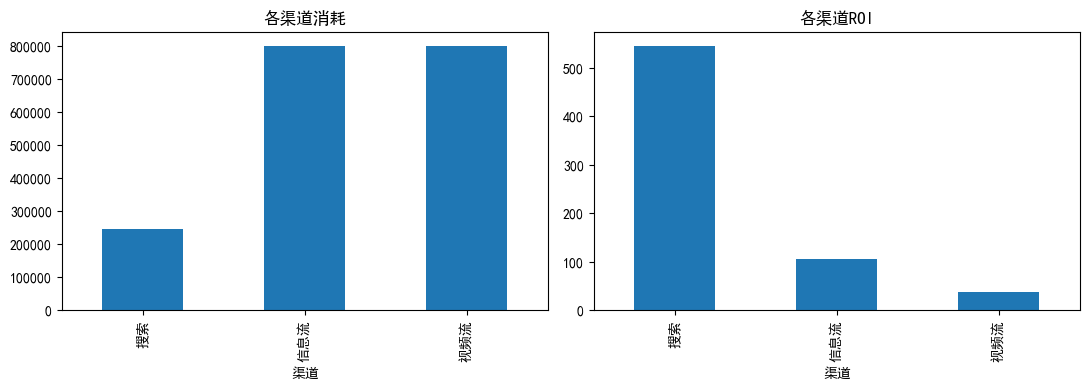

In [11]:
# 渠道消耗 vs ROI
fig, ax = plt.subplots(1,2, figsize=(11,4))
ch['消耗'].plot(kind='bar', ax=ax[0], title='各渠道消耗')
ch['ROI'].plot(kind='bar', ax=ax[1], title='各渠道ROI')
plt.tight_layout()

<Axes: title={'center': '每日消耗与转化趋势'}, xlabel='日期'>

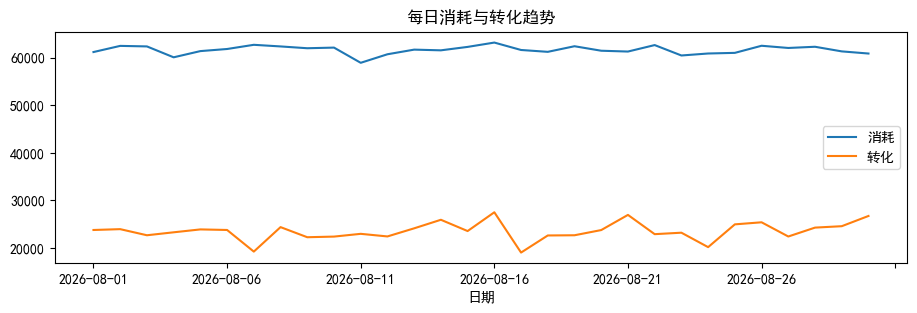

In [12]:
# 每日趋势
daily = df.groupby('日期').agg(消耗=('消耗','sum'), 转化=('转化数','sum'))
daily.plot(figsize=(11,3), title='每日消耗与转化趋势')

## 第7步：结论
（1）发现问题：30 天消耗约了 185 万。视频流渠道消耗占 43%（80 万），但 ROI 仅 38、CPA 高达 6.5 元，是全账户效率最低的效果非常差的；搜索渠道消耗仅占 13%（24.6 万），ROI 却高达 546、CPA 仅 0.83 元，效率最高效果最好但是占比太低了；信息流渠道消耗占比 43%（80 万），ROI 达 106、CPA2.8，处于比较中规中矩的数据但是主力数据

（2）建议动作：将视频流预算压低到 30% 左右，适当提高搜索渠道占比，优先淘汰 ROI 效率最低的渠道，腾出预算给搜索渠道

（3）在总预算不变前提下，24 万从视频流（ROI 38）转到搜索（ROI 546），预计带来的转化价值从约 900 万提升到约 1.3 亿，等效转化数从 3.7 万提升到约 29 万